# Agrupamento de categorias e recomendação com K-means

O objetivo é **agrupar categorias de produtos por padrões de consumo semelhantes**
e recomendar uma categoria compatível com o comportamento de cada cliente.
Cada observação usada no treinamento representa uma categoria, descrita pelas
compras de seus produtos. O nome da categoria é apenas um identificador.

O fluxo é: histórico de vendas → perfis de categorias e clientes → padronização →
K-means → predição do grupo do cliente → ordenação das categorias desse grupo.
A primeira categoria do resultado é a recomendação principal. Clientes sem
histórico recebem as categorias mais populares.

Dependências: `numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn` e `IPython`.
Execute as células em ordem, a partir da raiz do projeto ou de `big-data/`.

In [1]:
import sqlite3
from contextlib import closing
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 120

caminhos_dw = [
    Path("datawarehouse/datawarehouse.db"),
    Path("big-data/datawarehouse/datawarehouse.db"),
]
DB_PATH = next((caminho for caminho in caminhos_dw if caminho.is_file()), caminhos_dw[0])
RANDOM_STATE = 42
MAX_K = 6
# None usa a data da última venda válida. Informe uma data para limitar o histórico.
DATA_REFERENCIA = None

## 1. Leitura do Data Warehouse

O SQLite é aberto somente para leitura. As dimensões são deduplicadas por suas
chaves antes dos cruzamentos, evitando contabilizar uma venda mais de uma vez.
Nenhuma tabela ou arquivo de dados é alterado.

In [2]:
def carregar_dados_dw(db_path=DB_PATH):
    db_path = Path(db_path).resolve()
    if not db_path.is_file():
        raise FileNotFoundError(f"Banco de dados não encontrado: {db_path}")

    with closing(sqlite3.connect(f"{db_path.as_uri()}?mode=ro", uri=True)) as conn:
        df_vendas = pd.read_sql_query(
            """
            SELECT id_venda, id_cliente, id_produto, id_tempo, quantidade,
                   desconto, valor_total, canal, forma_pagamento
            FROM fato_vendas
            """, conn
        )
        df_clientes = pd.read_sql_query("SELECT * FROM dim_cliente", conn)
        df_produtos = pd.read_sql_query(
            "SELECT id_produto, categoria FROM dim_produto", conn
        )
        df_tempo = pd.read_sql_query("SELECT id_tempo, data AS data_venda FROM dim_tempo", conn)

    df_clientes = df_clientes.dropna(subset=["id_cliente"]).drop_duplicates("id_cliente")
    df_produtos = df_produtos.drop_duplicates("id_produto")
    df_tempo = df_tempo.drop_duplicates("id_tempo")
    df_vendas = (
        df_vendas.drop_duplicates("id_venda")
        .merge(df_produtos, on="id_produto", how="left", validate="many_to_one")
        .merge(df_tempo, on="id_tempo", how="left", validate="many_to_one")
    )
    for coluna in ["quantidade", "desconto", "valor_total"]:
        df_vendas[coluna] = pd.to_numeric(df_vendas[coluna], errors="coerce")
    df_vendas["data_venda"] = pd.to_datetime(df_vendas["data_venda"], errors="coerce")
    df_vendas["categoria"] = df_vendas["categoria"].astype("string").str.strip().replace("", pd.NA)
    return df_clientes, df_vendas

## 2. Atributos comportamentais comparáveis

Categorias e clientes recebem **os mesmos atributos**, calculados por compra:
ticket médio, quantidade média de itens, desconto relativo médio, proporções
de compras com desconto, no crediário e online, e recência média em dias.
O desconto relativo é `desconto / (valor_total + desconto)`.

Totais de compras servem para descrever os dados e calcular popularidade; não
entram nas distâncias, pois os volumes de uma categoria e de um cliente têm
escalas distintas. IDs, nomes de categorias e dados pessoais não são atributos
do K-means. Categorias sem vendas válidas não participam do agrupamento.

São descartadas vendas sem categoria, data, quantidade ou valor válidos.
Descontos ausentes são tratados como zero. A mesma data de referência é usada
nos dois perfis; vendas posteriores a ela não participam dos cálculos.

In [3]:
ATRIBUTOS = [
    "ticket_medio", "qtd_media_itens", "desconto_relativo_medio",
    "proporcao_promocao", "proporcao_crediario", "proporcao_online",
    "recencia_media_dias",
]


def resumir_comportamento(vendas, chave):
    return vendas.groupby(chave).agg(
        total_compras=("id_venda", "nunique"),
        ticket_medio=("valor_total", "mean"),
        qtd_media_itens=("quantidade", "mean"),
        desconto_relativo_medio=("desconto_relativo", "mean"),
        proporcao_promocao=("teve_desconto", "mean"),
        proporcao_crediario=("pagou_crediario", "mean"),
        proporcao_online=("compra_online", "mean"),
        recencia_media_dias=("dias_desde_compra", "mean"),
    )


def criar_atributos(df_clientes, df_vendas, data_referencia=None):
    vendas = df_vendas.copy()
    valores = ["quantidade", "desconto", "valor_total"]
    vendas[valores] = vendas[valores].replace([np.inf, -np.inf], np.nan)
    vendas["desconto"] = vendas["desconto"].fillna(0.0)
    vendas = vendas.dropna(subset=["categoria", "data_venda", "quantidade", "valor_total"])
    vendas = vendas.loc[
        (vendas["quantidade"] > 0) & (vendas["valor_total"] > 0) & (vendas["desconto"] >= 0)
    ].copy()
    if vendas.empty:
        raise ValueError("Não há vendas válidas para criar os perfis de consumo.")

    if data_referencia is None:
        data_referencia = vendas["data_venda"].max().normalize()
    else:
        data_referencia = pd.Timestamp(data_referencia).normalize()
        if pd.isna(data_referencia):
            raise ValueError("A data de referência deve ser válida.")
    vendas = vendas.loc[vendas["data_venda"].dt.normalize() <= data_referencia].copy()
    if vendas.empty:
        raise ValueError("Não há vendas válidas até a data de referência informada.")

    vendas["desconto_relativo"] = vendas["desconto"] / (vendas["valor_total"] + vendas["desconto"])
    vendas["teve_desconto"] = (vendas["desconto"] > 0).astype(float)
    vendas["pagou_crediario"] = (
        vendas["forma_pagamento"].astype("string").str.strip().str.casefold()
        .eq("crediário").fillna(False).astype(float)
    )
    vendas["compra_online"] = (
        vendas["canal"].astype("string").str.strip().str.casefold()
        .eq("online").fillna(False).astype(float)
    )
    vendas["dias_desde_compra"] = (
        data_referencia - vendas["data_venda"].dt.normalize()
    ).dt.days

    df_categorias = resumir_comportamento(vendas, "categoria")
    perfis = resumir_comportamento(vendas.dropna(subset=["id_cliente"]), "id_cliente")
    df_perfis_clientes = (
        df_clientes[["id_cliente"]].drop_duplicates("id_cliente")
        .merge(perfis.reset_index(), on="id_cliente", how="left", validate="one_to_one")
    )
    df_perfis_clientes["total_compras"] = df_perfis_clientes["total_compras"].fillna(0).astype(int)
    print(f"Data de referência: {data_referencia.date()} | Vendas utilizadas: {len(vendas)}")
    return df_categorias, df_perfis_clientes, data_referencia

## 3. Treinamento não supervisionado e seleção de K

O pipeline aplica imputação por mediana, `StandardScaler` e K-means com
inicializações repetidas e semente fixa. Somente os perfis das categorias são
usados para ajustar essas etapas. O mesmo pipeline transforma os clientes na
predição, sem reajustar o modelo.

Testamos de 2 até `MAX_K` grupos, respeitando o número de categorias e de perfis
distintos. Escolhemos a maior silhueta média; em empate, o menor K. A inércia é
registrada para inspeção. Se não houver uma partição avaliável, usamos um único
grupo e deixamos a silhueta indisponível.

In [4]:
def preparar_pipeline(n_clusters):
    return Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scaler", StandardScaler()),
        ("kmeans", KMeans(n_clusters=n_clusters, n_init=20, random_state=RANDOM_STATE)),
    ])


def treinar_agrupamento(df_categorias, max_k=MAX_K):
    if df_categorias.empty:
        raise ValueError("É necessária pelo menos uma categoria com histórico.")
    if not isinstance(max_k, (int, np.integer)) or max_k < 1:
        raise ValueError("max_k deve ser um inteiro positivo.")

    X = df_categorias[ATRIBUTOS].replace([np.inf, -np.inf], np.nan)
    melhor_modelo = preparar_pipeline(1).fit(X)
    X_padronizado = melhor_modelo[:-1].transform(X)
    n_distintos = len(np.unique(X_padronizado, axis=0))
    limite_k = min(max_k, len(X) - 1, n_distintos)
    melhor_silhueta = -np.inf
    resultados = []

    for k in range(2, limite_k + 1):
        modelo = preparar_pipeline(k).fit(X)
        grupos = modelo.named_steps["kmeans"].labels_
        n_grupos = len(np.unique(grupos))
        silhueta = (
            silhouette_score(X_padronizado, grupos)
            if 2 <= n_grupos < len(X) else np.nan
        )
        resultados.append({
            "k": k, "grupos_observados": n_grupos,
            "inercia": modelo.named_steps["kmeans"].inertia_, "silhueta": silhueta,
        })
        if pd.notna(silhueta) and silhueta > melhor_silhueta:
            melhor_modelo = modelo
            melhor_silhueta = silhueta

    if melhor_silhueta == -np.inf:
        resultados.append({
            "k": 1, "grupos_observados": 1,
            "inercia": melhor_modelo.named_steps["kmeans"].inertia_, "silhueta": np.nan,
        })

    categorias_agrupadas = df_categorias.copy()
    categorias_agrupadas["grupo"] = melhor_modelo.predict(X)
    metricas = pd.DataFrame(resultados).sort_values("k").reset_index(drop=True)
    k_escolhido = melhor_modelo.named_steps["kmeans"].n_clusters
    print(f"K selecionado: {k_escolhido} | Categorias agrupadas: {len(X)}")
    if melhor_silhueta > -np.inf:
        print(f"Silhueta média: {melhor_silhueta:.4f}")
    else:
        print("Silhueta indisponível: dados insuficientes para comparar grupos.")
    return melhor_modelo, categorias_agrupadas, metricas

In [5]:
def gerar_visualizacoes(modelo, categorias_agrupadas, metricas):
    k_escolhido = modelo.named_steps["kmeans"].n_clusters
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, metrica, titulo in zip(
        axes, ["inercia", "silhueta"], ["Inércia por K", "Silhueta média por K"]
    ):
        validas = metricas.dropna(subset=[metrica])
        if validas.empty:
            ax.text(0.5, 0.5, "Métrica indisponível", ha="center", va="center", transform=ax.transAxes)
        else:
            ax.plot(validas["k"], validas[metrica], marker="o")
        ax.axvline(k_escolhido, color="tab:red", linestyle="--", label=f"K escolhido = {k_escolhido}")
        ax.set(title=titulo, xlabel="Número de grupos (K)", ylabel=metrica.capitalize())
        ax.set_xticks(metricas["k"])
        ax.legend()
    plt.tight_layout()
    plt.show()

    ordenadas = categorias_agrupadas.sort_values("grupo", kind="stable")
    perfis = pd.DataFrame(
        modelo[:-1].transform(ordenadas[ATRIBUTOS]),
        index=[f"{categoria} (grupo {grupo})" for categoria, grupo in ordenadas["grupo"].items()],
        columns=ATRIBUTOS,
    )
    fig, ax = plt.subplots(figsize=(11, max(3, len(perfis) * 0.55)))
    sns.heatmap(perfis, annot=True, fmt=".1f", cmap="vlag", center=0, ax=ax)
    ax.set_title("Perfis padronizados das categorias por grupo")
    ax.set_xlabel("Atributos comportamentais (valores em desvios padrão)")
    ax.set_ylabel("Categoria e grupo")
    plt.tight_layout()
    plt.show()

## 4. Predição do grupo e recomendação da categoria

Para um cliente com histórico, `predict` identifica o centroide mais próximo do
seu perfil comportamental. As categorias pertencentes a esse grupo são ordenadas
pela distância euclidiana ao perfil do cliente, no mesmo espaço padronizado.
Quanto menor a distância, maior a compatibilidade segundo esses atributos.
Em empate, usamos o nome da categoria para manter o resultado determinístico.

`top_n` é o máximo de recomendações: um grupo menor pode retornar menos categorias.
Para um cliente desconhecido ou sem compras válidas, o retorno usa a popularidade
no histórico considerado. Nesse caso, não há distância a um perfil de cliente.
As distâncias **não representam probabilidades de compra**.

In [6]:
def obter_categorias_fallback(categorias_agrupadas, top_n=3):
    if not isinstance(top_n, (int, np.integer)) or top_n < 1:
        raise ValueError("top_n deve ser um inteiro positivo.")
    ranking = (
        categorias_agrupadas.reset_index()
        .sort_values(["total_compras", "categoria"], ascending=[False, True])
        .head(top_n).copy()
    )
    ranking["Distância ao Perfil"] = np.nan
    ranking["Origem"] = "Popularidade (sem histórico)"
    return ranking.rename(columns={"categoria": "Categoria Recomendada", "grupo": "Grupo"})[
        ["Categoria Recomendada", "Grupo", "Distância ao Perfil", "Origem"]
    ].reset_index(drop=True)


def recomendar_para_cliente(modelo, categorias_agrupadas, df_perfis_clientes, id_cliente, top_n=3):
    if not isinstance(top_n, (int, np.integer)) or top_n < 1:
        raise ValueError("top_n deve ser um inteiro positivo.")
    cliente = df_perfis_clientes.loc[df_perfis_clientes["id_cliente"] == id_cliente]
    if cliente.empty or cliente["total_compras"].iloc[0] == 0:
        return obter_categorias_fallback(categorias_agrupadas, top_n=top_n)

    X_cliente = cliente[ATRIBUTOS].replace([np.inf, -np.inf], np.nan)
    grupo_predito = int(modelo.predict(X_cliente)[0])
    candidatas = categorias_agrupadas.loc[
        categorias_agrupadas["grupo"] == grupo_predito
    ].copy()
    perfil_padronizado = modelo[:-1].transform(X_cliente)
    categorias_padronizadas = modelo[:-1].transform(candidatas[ATRIBUTOS])
    candidatas["Distância ao Perfil"] = np.linalg.norm(
        categorias_padronizadas - perfil_padronizado, axis=1
    )
    ranking = (
        candidatas.reset_index()
        .sort_values(["Distância ao Perfil", "categoria"])
        .head(top_n).copy()
    )
    ranking["Origem"] = "K-means e distância ao perfil"
    return ranking.rename(columns={"categoria": "Categoria Recomendada", "grupo": "Grupo"})[
        ["Categoria Recomendada", "Grupo", "Distância ao Perfil", "Origem"]
    ].reset_index(drop=True)

Data de referência: 2026-11-06 | Vendas utilizadas: 14806
K selecionado: 2 | Categorias agrupadas: 7
Silhueta média: 0.2946

Avaliação dos agrupamentos:


,k,grupos_observados,inercia,silhueta
0,2,2,29.412307,0.294647
1,3,3,18.291299,0.185568
2,4,4,12.011882,0.065664
3,5,5,6.323897,0.070577
4,6,6,1.918094,0.065918



Categorias e seus grupos:


,total_compras,ticket_medio,qtd_media_itens,desconto_relativo_medio,proporcao_promocao,proporcao_crediario,proporcao_online,recencia_media_dias,grupo
categoria,,,,,,,,,
Acessório,1918,548.667059,3.004692,0.049010,0.489051,0.112096,0.498436,126.511470,0
Bermuda,1874,463.848154,2.991462,0.052295,0.510672,0.098719,0.502668,126.739061,0
Blusa,2317,516.638964,2.985326,0.047950,0.482952,0.097540,0.484247,126.931808,0
Camiseta,2465,505.082897,2.989858,0.049168,0.496957,0.104665,0.500203,123.479513,0
Jaqueta,2019,542.704819,3.010896,0.049629,0.493314,0.103021,0.492323,127.361565,0
Vestido,2014,622.214101,3.014399,0.049181,0.500993,0.094836,0.498510,125.686197,0
Calça,2199,650.371446,3.044566,0.048295,0.480673,0.107776,0.516598,122.816280,1


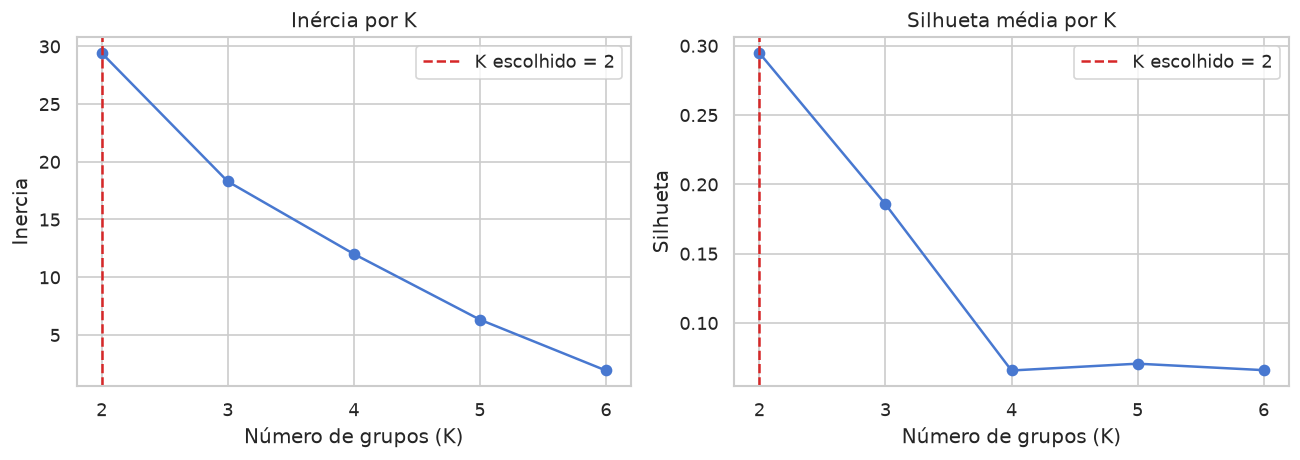

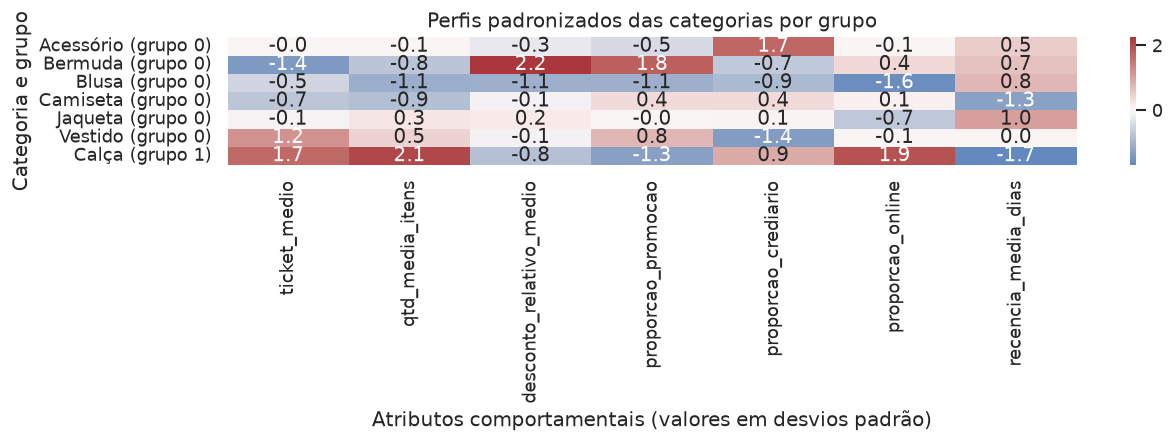

In [7]:
df_clientes, df_vendas = carregar_dados_dw()
df_categorias, df_perfis_clientes, data_referencia = criar_atributos(
    df_clientes, df_vendas, data_referencia=DATA_REFERENCIA
)
modelo, categorias_agrupadas, metricas = treinar_agrupamento(df_categorias)

print("\nAvaliação dos agrupamentos:")
display(metricas)
print("\nCategorias e seus grupos:")
display(categorias_agrupadas.sort_values("grupo", kind="stable"))
gerar_visualizacoes(modelo, categorias_agrupadas, metricas)

In [8]:
ids_com_historico = df_perfis_clientes.loc[
    df_perfis_clientes["total_compras"] > 0, "id_cliente"
].head(2)
for id_cliente in ids_com_historico:
    recomendacoes = recomendar_para_cliente(
        modelo, categorias_agrupadas, df_perfis_clientes, id_cliente, top_n=3
    )
    print(f"\nCliente {id_cliente} — categoria principal: {recomendacoes.iloc[0]['Categoria Recomendada']}")
    display(recomendacoes)

ids_sem_historico = df_perfis_clientes.loc[
    df_perfis_clientes["total_compras"] == 0, "id_cliente"
]
id_sem_historico = (
    ids_sem_historico.iloc[0] if not ids_sem_historico.empty
    else int(df_perfis_clientes["id_cliente"].max()) + 1 if not df_perfis_clientes.empty else 1
)
print(f"\nCliente sem histórico / novo (ID = {id_sem_historico}):")
display(recomendar_para_cliente(
    modelo, categorias_agrupadas, df_perfis_clientes, id_sem_historico, top_n=3
))


Cliente 1 — categoria principal: Calça


,Categoria Recomendada,Grupo,Distância ao Perfil,Origem
0,Calça,1,23.064814,K-means e distância ao perfil



Cliente 2 — categoria principal: Bermuda


,Categoria Recomendada,Grupo,Distância ao Perfil,Origem
0,Bermuda,0,9.591416,K-means e distância ao perfil
1,Jaqueta,0,11.436977,K-means e distância ao perfil
2,Vestido,0,12.025964,K-means e distância ao perfil



Cliente sem histórico / novo (ID = 601):


,Categoria Recomendada,Grupo,Distância ao Perfil,Origem
0,Camiseta,0,NaN,Popularidade (sem histórico)
1,Blusa,0,NaN,Popularidade (sem histórico)
2,Calça,1,NaN,Popularidade (sem histórico)


## Interpretação e referências

Os números dos grupos são identificadores, sem ordem de preferência. A silhueta
mede a separação dos perfis das categorias; a inércia mede sua dispersão em torno
dos centroides. Com poucas categorias, esses resultados são descritivos e devem
ser interpretados junto aos perfis apresentados.

A recomendação é uma heurística de compatibilidade comportamental. Não foi
medida a capacidade de antecipar a próxima compra: isso exige separar o histórico
por tempo e comparar as recomendações com compras posteriores, usando métricas
como acerto em top-K. A silhueta não substitui essa avaliação.

Documentação do scikit-learn:
[K-means e predição do grupo](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html),
[StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) e
[coeficiente de silhueta](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).